# FinGuard: Shared Training and Evaluation
**Explainable ML for UPI fraud detection (Module A) and loan credit risk scoring (Module B)**

Both modules share one preprocessing pipeline, one model zoo and one evaluation framework, so results are directly comparable.

| Step | What we do | Syllabus link |
|---|---|---|
| 1 | Load and explore data | Unit II preprocessing |
| 2 | Pipelines (impute, scale, one-hot) fit on training folds only | Unit II |
| 3 | Stratified 5-fold CV over 8 algorithms | Unit IV model selection |
| 4 | Imbalance: none vs class weights vs SMOTE | Unit II/V |
| 5 | Hold-out evaluation: confusion matrix, PR, ROC, AUC, log-loss | Unit II metrics |
| 6 | Threshold tuning for business cost | |
| 7 | Isolation Forest (unsupervised) | Unit V |
| 8 | Bias-variance learning curve | Unit II |
| 9 | SHAP explainability and credit score / reason codes | |

**Important:** both datasets are *synthetic* (generated by `src/generate_data.py`). Say so in your report.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import train_utils as tu

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
upi = pd.read_csv(ROOT / "data" / "upi_transactions.csv")
credit = pd.read_csv(ROOT / "data" / "credit_risk.csv")
print("UPI   :", upi.shape, "| fraud rate   :", round(upi.is_fraud.mean(), 4))
print("Credit:", credit.shape, "| default rate :", round(credit["default"].mean(), 4))

UPI   : (30000, 25) | fraud rate   : 0.0173
Credit: (15000, 17) | default rate : 0.0957


## 1. Exploratory data analysis

In [2]:
print("Missing values (UPI):\n", upi.isna().sum()[lambda s: s > 0], "\n")
print("Missing values (Credit):\n", credit.isna().sum()[lambda s: s > 0], "\n")
print("Fraud by type:\n", upi.groupby("fraud_type").is_fraud.agg(["count", "sum"]), "\n")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
upi.groupby("hour").is_fraud.mean().plot(ax=ax[0], marker="o"); ax[0].set(title="UPI fraud rate by hour")
upi.groupby("device_changed").is_fraud.mean().plot.bar(ax=ax[1]); ax[1].set(title="Fraud rate: device changed?")
credit.groupby("missed_payments_2y")["default"].mean().head(6).plot.bar(ax=ax[2]); ax[2].set(title="Default rate by missed payments")
plt.tight_layout(); fig.savefig(tu.REPORTS_DIR / "eda_overview.png", dpi=130); plt.show()

Missing values (UPI):
 payee_vpa_age_days     477
balance_after_ratio    444
dtype: int64 

Missing values (Credit):
 employment_years        302
credit_history_years    315
dtype: int64 

Fraud by type:
                  count  sum
fraud_type                 
collect_scam       174  174
fake_qr            108  108
legit_emergency    360    1
mule_passthru      108  108
none             29190   67
sim_swap            60   60 



## 2. Module A: UPI fraud detection
Leakage guard: `txn_id` and `fraud_type` are dropped (`fraud_type` is literally the answer).

In [3]:
TARGET_A = "is_fraud"
DROP_A = ["txn_id", "fraud_type"]
pre_A, feats_A = tu.make_preprocessor(upi, TARGET_A, DROP_A)
XA, yA = upi[feats_A], upi[TARGET_A]
XA_tr, XA_te, yA_tr, yA_te = train_test_split(XA, yA, test_size=0.2, stratify=yA, random_state=tu.RANDOM_STATE)
print("train:", XA_tr.shape, "test:", XA_te.shape, "| fraud in test:", int(yA_te.sum()))

train: (24000, 21) test: (6000, 21) | fraud in test: 104


### 2.1 Stratified 5-fold CV: all models, class weights

In [4]:
models_cw = tu.get_models("class_weight")
cv_A = tu.cross_validate_models(XA_tr, yA_tr, pre_A, models_cw, imbalance="class_weight")
cv_A.round(4)

  Logistic Regression    PR-AUC=0.666  ROC-AUC=0.933  F1=0.344


  Naive Bayes            PR-AUC=0.313  ROC-AUC=0.927  F1=0.370


  Decision Tree          PR-AUC=0.751  ROC-AUC=0.923  F1=0.423


  kNN                    PR-AUC=0.789  ROC-AUC=0.944  F1=0.712


  SVM (RBF)              PR-AUC=0.747  ROC-AUC=0.956  F1=0.668


  Random Forest          PR-AUC=0.880  ROC-AUC=0.940  F1=0.907


  AdaBoost               PR-AUC=0.861  ROC-AUC=0.932  F1=0.827


  MLP                    PR-AUC=0.851  ROC-AUC=0.947  F1=0.803


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Log-loss,PR-AUC std
0,Random Forest,0.9588,0.8623,0.9069,0.9405,0.8797,0.0433,0.0414
1,AdaBoost,0.9802,0.7150,0.8268,0.9320,0.8609,0.3043,0.0244
2,MLP (subsample 8000),0.9449,0.7026,0.8031,0.9470,0.8511,0.0268,0.0306
3,kNN (subsample 8000),0.9573,0.5714,0.7123,0.9442,0.7893,0.0832,0.0436
4,Decision Tree,0.2818,0.8647,0.4233,0.9230,0.7513,0.1483,0.0362
5,SVM (RBF) (subsample 8000),0.6905,0.6603,0.6676,0.9564,0.7465,0.0336,0.0390
6,Logistic Regression,0.2139,0.8840,0.3440,0.9330,0.6662,0.2128,0.0322
7,Naive Bayes,0.3323,0.4226,0.3700,0.9267,0.3126,0.5203,0.0253


### 2.2 Imbalance strategies compared (none vs class weights vs SMOTE)
SMOTE sits *inside* the pipeline, so it only touches training folds (no leakage).

In [5]:
subset = ["Logistic Regression", "Decision Tree", "Random Forest"]
rows = []
for strat in ["none", "class_weight", "smote"]:
    m = {k: v for k, v in tu.get_models(strat).items() if k in subset}
    r = tu.cross_validate_models(XA_tr, yA_tr, pre_A, m, imbalance=strat, verbose=False)
    r.insert(0, "Strategy", strat); rows.append(r)
imb_A = pd.concat(rows)[["Strategy", "Model", "Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]]
imb_A.round(4)

,Strategy,Model,Precision,Recall,F1,PR-AUC,ROC-AUC
0,none,Random Forest,0.9888,0.8406,0.9080,0.8797,0.9455
1,none,Decision Tree,0.9589,0.8237,0.8852,0.8455,0.9278
2,none,Logistic Regression,0.8767,0.6160,0.7213,0.8016,0.9326
0,class_weight,Random Forest,0.9588,0.8623,0.9069,0.8797,0.9405
1,class_weight,Decision Tree,0.2818,0.8647,0.4233,0.7513,0.9230
2,class_weight,Logistic Regression,0.2139,0.8840,0.3440,0.6662,0.9330
0,smote,Random Forest,0.9445,0.8526,0.8955,0.8795,0.9456
1,smote,Decision Tree,0.5457,0.8140,0.6522,0.7256,0.9203
2,smote,Logistic Regression,0.2299,0.8744,0.3635,0.6617,0.9319


### 2.3 Hold-out test evaluation

In [6]:
fitted_A, scores_A = tu.fit_all_holdout(XA_tr, yA_tr, XA_te, pre_A, models_cw)
hold_A = pd.DataFrame({n: tu.holdout_metrics(yA_te, s) for n, s in scores_A.items()}).T.sort_values("PR-AUC", ascending=False)
hold_A.round(4)

,Precision,Recall,F1,ROC-AUC,PR-AUC,Log-loss,KS
Random Forest,0.9778,0.8462,0.9072,0.9246,0.8595,0.0406,0.8462
AdaBoost,0.9744,0.7308,0.8352,0.9278,0.8488,0.2954,0.8434
MLP,0.9231,0.6923,0.7912,0.9166,0.8066,0.0327,0.8242
Decision Tree,0.2825,0.8365,0.4223,0.9265,0.7527,0.1339,0.8269
kNN,1.0000,0.5000,0.6667,0.9028,0.7330,0.0580,0.7758
SVM (RBF),0.7317,0.5769,0.6452,0.9254,0.6898,0.0406,0.8054
Logistic Regression,0.2138,0.8654,0.3429,0.9218,0.6235,0.2114,0.8359
Naive Bayes,0.2479,0.2885,0.2667,0.9190,0.2604,0.3041,0.7857


Best model on hold-out PR-AUC: Random Forest


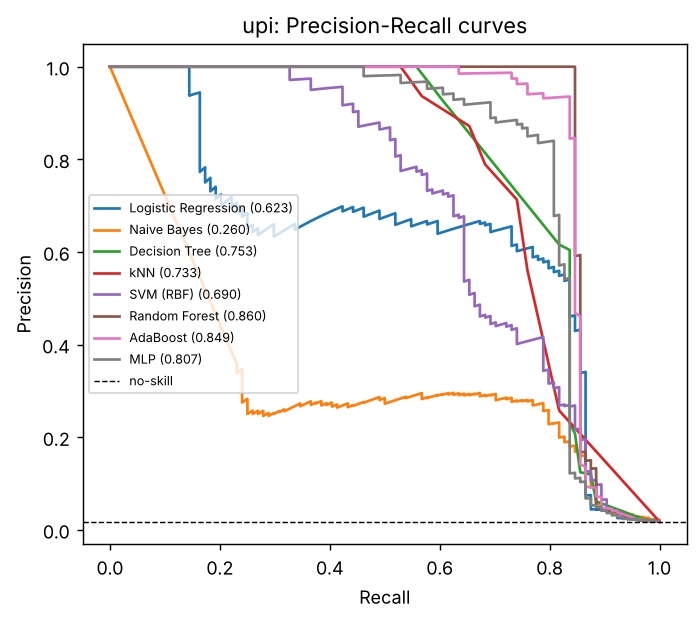

In [7]:
tu.plot_roc_pr(scores_A, yA_te, "upi")
tu.plot_model_comparison(cv_A, "UPI fraud: 5-fold CV PR-AUC", "upi_model_comparison.png")
best_A = hold_A.index[0]
print("Best model on hold-out PR-AUC:", best_A)
from IPython.display import Image, display
display(Image(str(tu.REPORTS_DIR / "upi_pr.png")))

### 2.4 Three-tier decisions: Allow / Verify / Block
A single fraud/not-fraud cut-off is not how real systems work. A high score should trigger **step-up verification** (OTP, biometric, callback), not an automatic block, so a genuine customer in an emergency is only briefly inconvenienced.

Thresholds are chosen on **out-of-fold predictions from the training data** (never the test set):
* **Block** when precision is at least 95% (be very sure before blocking)
* **Verify** when recall is at least 95%, but capped so that at most 5% of all traffic is ever sent to verification (review capacity)

In [8]:
from sklearn.base import clone
DEPLOY_A = "Random Forest"   # tree model: supports SHAP and is saved for the demo
oof_A = tu.oof_scores(tu.build_pipeline(clone(pre_A), tu.get_models("class_weight")[DEPLOY_A]), XA_tr, yA_tr)
tiers_A = tu.choose_tiers(yA_tr, oof_A, block_precision=0.95, verify_recall=0.95, max_review_share=0.05)
print("Thresholds chosen on training OOF:", {k: round(v, 3) for k, v in tiers_A.items()})

s = scores_A[DEPLOY_A]
tier_A = tu.apply_tiers(s, tiers_A)
ft_te = upi.loc[XA_te.index, "fraud_type"].values
rep = tu.tier_report(tier_A, yA_te.values, ft_te)
display(rep)
print("Genuine emergencies blocked:", int(rep.loc["Block", "genuine_emergencies"]),
      "| sent to Verify:", int(rep.loc["Verify", "genuine_emergencies"]),
      "| allowed:", int(rep.loc["Allow", "genuine_emergencies"]))
print("Real fraud caught (Verify + Block):", int(rep.loc[["Verify", "Block"], "real_fraud"].sum()), "of", int(rep["real_fraud"].sum()))
print(pd.crosstab(ft_te, tier_A).reindex(columns=["Allow", "Verify", "Block"], fill_value=0))
tu.plot_confusion(yA_te, s, tiers_A["block"], f"UPI: {DEPLOY_A} (block threshold)", "upi_confusion.png")
rep.to_csv(tu.REPORTS_DIR / "upi_tier_report.csv")
THRESH_A = tiers_A["verify"]

Thresholds chosen on training OOF: {'verify': 0.093, 'block': 0.459}


,transactions,real_fraud,genuine_emergencies,share_of_traffic_%
tier,,,,
Allow,5701,15,36,95.02
Verify,207,1,37,3.45
Block,92,88,0,1.53


Genuine emergencies blocked: 0 | sent to Verify: 37 | allowed: 36
Real fraud caught (Verify + Block): 89 of 104
col_0            Allow  Verify  Block
row_0                                
collect_scam         0       1     42
fake_qr              0       0     23
legit_emergency     36      37      0
mule_passthru        0       0     15
none              5665     169      4
sim_swap             0       0      8


### 2.4b The emergency scenario
A customer with a **new account, a SIM change 7 days ago, a 2 am payment of Rs 25,000 (31x their average) that leaves 2% of their balance**: exactly the profile that looked like fraud. We change the *context* one signal at a time.

In [9]:
base = dict(hour=2, day_of_week=2, account_age_days=5, avg_user_amount=800, txn_count_1h=1, txn_count_24h=2,
            payee_vpa_age_days=400, device_changed=0, sim_changed_7d=1, is_collect_request=0, payee_type="merchant",
            balance_after_ratio=0.02, amount=25000, amount_to_avg_ratio=31.25, is_night=1, is_round_amount=1,
            payee_prior_txn_count=0, payee_category="medical", location_match=1, amount_to_max_past_ratio=6.25,
            is_new_payee=1)
cases = {
    "Emergency: hospital payee, same device, usual place": {},
    "Same, but payee is an unknown VPA": {"payee_category": "other"},
    "Emergency, payee is a known contact": {"payee_prior_txn_count": 6, "is_new_payee": 0, "payee_category": "individual"},
    "Account takeover: new device, unknown payee, odd place": {"payee_category": "other", "device_changed": 1,
                                                              "location_match": 0, "payee_vpa_age_days": 4},
}
rows = []
for name, ch in cases.items():
    r = pd.DataFrame([{**base, **ch}])[feats_A]
    p = float(fitted_A[DEPLOY_A].predict_proba(r)[0, 1])
    rows.append({"scenario": name, "fraud probability": round(p, 3), "decision": tu.apply_tiers([p], tiers_A)[0]})
display(pd.DataFrame(rows))

,scenario,fraud probability,decision
0,"Emergency: hospital payee, same device, usual ...",0.341,Verify
1,"Same, but payee is an unknown VPA",0.427,Verify
2,"Emergency, payee is a known contact",0.227,Verify
3,"Account takeover: new device, unknown payee, o...",0.698,Block


### 2.5 Unsupervised anomaly detection: Isolation Forest (no labels used for training)

In [10]:
from sklearn.metrics import roc_auc_score, average_precision_score
pre_iso, _ = tu.make_preprocessor(upi, TARGET_A, DROP_A)
Xtr_p = pre_iso.fit_transform(XA_tr); Xte_p = pre_iso.transform(XA_te)
iso_scores, iso = tu.isolation_forest_scores(Xtr_p, Xte_p, contamination=float(yA_tr.mean()))
print(f"Isolation Forest  ROC-AUC={roc_auc_score(yA_te, iso_scores):.3f}  PR-AUC={average_precision_score(yA_te, iso_scores):.3f}")
print(f"Supervised {best_A:<16} ROC-AUC={hold_A.loc[best_A,'ROC-AUC']:.3f}  PR-AUC={hold_A.loc[best_A,'PR-AUC']:.3f}")

Isolation Forest  ROC-AUC=0.890  PR-AUC=0.351
Supervised Random Forest    ROC-AUC=0.925  PR-AUC=0.860


### 2.6 Bias-variance diagnostic (learning curve)

In [11]:
from sklearn.base import clone
pipe_lc = tu.build_pipeline(clone(pre_A), tu.get_models("class_weight")["Random Forest"])
sz, tr, va = tu.bias_variance_curve(pipe_lc, XA_tr, yA_tr)
tu.plot_learning_curve(sz, tr, va, "UPI Random Forest: learning curve", "upi_learning_curve.png")
print(pd.DataFrame({"train_size": sz, "train PR-AUC": tr.round(3), "val PR-AUC": va.round(3)}))

   train_size  train PR-AUC  val PR-AUC
0        1600           1.0       0.818
1        3200           1.0       0.864
2        6400           1.0       0.872
3        9600           1.0       0.878
4       12800           1.0       0.879
5       16000           1.0       0.880


### 2.7 Explainability: SHAP (Random Forest)

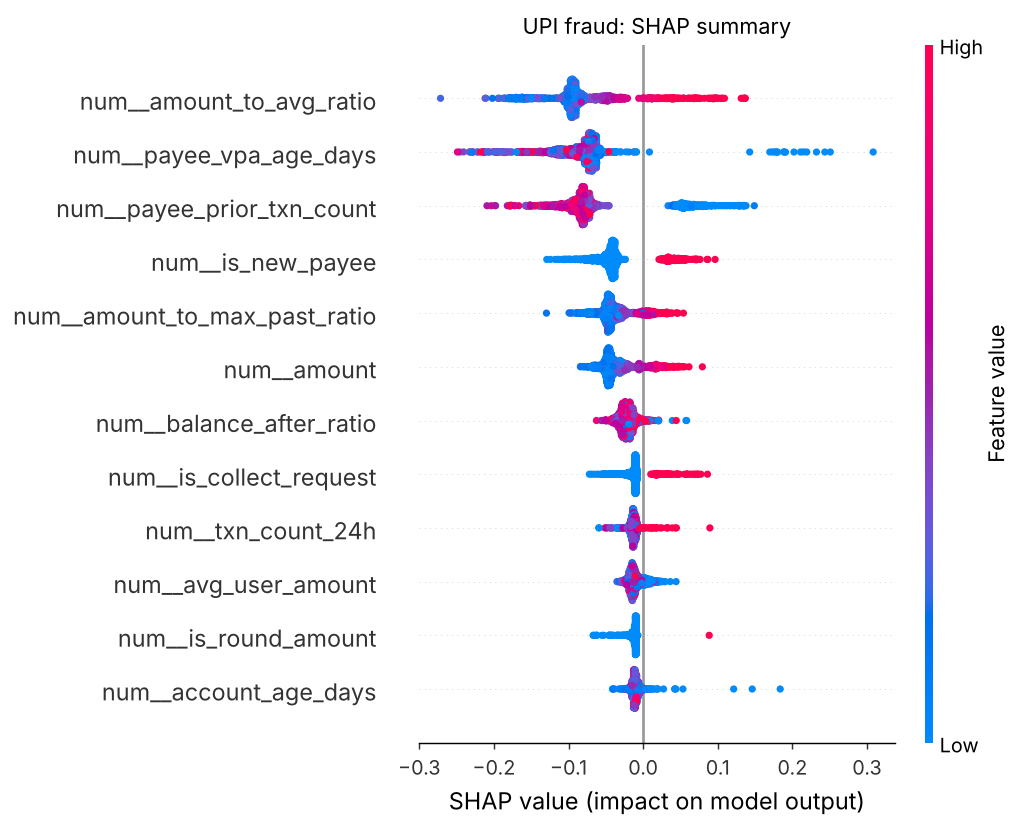

Risk score: 1.0 | actual label: 1
Top reasons (SHAP contribution toward fraud):
num__payee_vpa_age_days       0.1868
num__payee_prior_txn_count    0.1308
num__amount_to_avg_ratio      0.0963
num__is_collect_request       0.0633
dtype: float64


In [12]:
rf_A = fitted_A["Random Forest"]
sv, names, _ = tu.shap_summary(rf_A, XA_te.sample(1500, random_state=1), "upi_shap_summary.png", "UPI fraud: SHAP summary")
display(Image(str(tu.REPORTS_DIR / "upi_shap_summary.png")))

# Local explanation for the riskiest test transaction
i = int(np.argmax(scores_A["Random Forest"]))
row = XA_te.iloc[[i]]
print("Risk score:", round(float(scores_A["Random Forest"][i]), 3), "| actual label:", int(yA_te.iloc[i]))
print("Top reasons (SHAP contribution toward fraud):")
print(tu.top_reasons(rf_A, row, k=4).round(4))

## 3. Module B: Loan credit risk scoring
`gender` is **excluded** from the model and used only in the fairness check below.

In [13]:
TARGET_B = "default"
DROP_B = ["applicant_id", "gender"]
pre_B, feats_B = tu.make_preprocessor(credit, TARGET_B, DROP_B)
XB, yB = credit[feats_B], credit[TARGET_B]
XB_tr, XB_te, yB_tr, yB_te = train_test_split(XB, yB, test_size=0.2, stratify=yB, random_state=tu.RANDOM_STATE)
cv_B = tu.cross_validate_models(XB_tr, yB_tr, pre_B, tu.get_models("class_weight"), imbalance="class_weight")
cv_B.round(4)

  Logistic Regression    PR-AUC=0.384  ROC-AUC=0.807  F1=0.344


  Naive Bayes            PR-AUC=0.331  ROC-AUC=0.770  F1=0.350


  Decision Tree          PR-AUC=0.231  ROC-AUC=0.685  F1=0.270


  kNN                    PR-AUC=0.237  ROC-AUC=0.699  F1=0.069


  SVM (RBF)              PR-AUC=0.277  ROC-AUC=0.752  F1=0.325


  Random Forest          PR-AUC=0.338  ROC-AUC=0.776  F1=0.363


  AdaBoost               PR-AUC=0.361  ROC-AUC=0.794  F1=0.124


  MLP                    PR-AUC=0.270  ROC-AUC=0.732  F1=0.074


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC,Log-loss,PR-AUC std
0,Logistic Regression,0.2251,0.7320,0.3442,0.8071,0.3841,0.5307,0.0238
1,AdaBoost,0.7498,0.0679,0.1238,0.7941,0.3615,0.4427,0.0203
2,Random Forest,0.3748,0.3533,0.3634,0.7757,0.3385,0.3517,0.0217
3,Naive Bayes,0.3792,0.3255,0.3502,0.7697,0.3311,0.3252,0.0311
4,SVM (RBF) (subsample 8000),0.2229,0.6019,0.3252,0.7524,0.2772,0.2774,0.0236
5,MLP (subsample 8000),0.5884,0.0418,0.0739,0.7317,0.2704,0.3117,0.0814
6,kNN (subsample 8000),0.6384,0.0366,0.0691,0.6991,0.2370,0.8521,0.0184
7,Decision Tree,0.1759,0.5796,0.2695,0.6851,0.2311,1.0535,0.0114


In [14]:
fitted_B, scores_B = tu.fit_all_holdout(XB_tr, yB_tr, XB_te, pre_B, tu.get_models("class_weight"))
hold_B = pd.DataFrame({n: tu.holdout_metrics(yB_te, s) for n, s in scores_B.items()}).T.sort_values("ROC-AUC", ascending=False)
display(hold_B.round(4))
tu.plot_roc_pr(scores_B, yB_te, "credit")
tu.plot_model_comparison(cv_B, "Credit risk: 5-fold CV PR-AUC", "credit_model_comparison.png")
best_B = hold_B.index[0]; print("Best model on hold-out ROC-AUC:", best_B)

,Precision,Recall,F1,ROC-AUC,PR-AUC,Log-loss,KS
Logistic Regression,0.2192,0.6829,0.3319,0.8008,0.3621,0.5243,0.4456
AdaBoost,0.7895,0.0523,0.0980,0.7938,0.3574,0.4446,0.4369
MLP,0.5667,0.0592,0.1073,0.7847,0.3363,0.2656,0.4373
Random Forest,0.3577,0.3066,0.3302,0.7765,0.3235,0.3492,0.4152
Naive Bayes,0.3772,0.2997,0.3340,0.7720,0.3118,0.3268,0.4377
SVM (RBF),0.5000,0.0139,0.0271,0.7699,0.2989,0.2708,0.4239
kNN,0.6429,0.0314,0.0598,0.7281,0.2559,0.3971,0.3311
Decision Tree,0.1838,0.5923,0.2805,0.7200,0.2336,0.6098,0.3447


Best model on hold-out ROC-AUC: Logistic Regression


### 3.1 Credit score (300-900), risk band and decision

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
sc_pipe = tu.build_pipeline(clone(pre_B), LogisticRegression(max_iter=1000, random_state=tu.RANDOM_STATE))
sc_pipe.fit(XB_tr, yB_tr)                        # NO class weights: probabilities stay calibrated for scoring
sB = sc_pipe.predict_proba(XB_te)[:, 1]
score = tu.pd_to_score(sB)
from sklearn.metrics import roc_auc_score
out = pd.DataFrame({"PD": sB.round(3), "score": score.round(0), "default": yB_te.values})
out["band"] = tu.risk_band(out["score"]).values
print("Scorecard ROC-AUC:", round(roc_auc_score(yB_te, sB), 3))
print(out.groupby("band", observed=True).agg(applicants=("PD", "size"), avg_PD=("PD", "mean"), actual_default_rate=("default", "mean")).round(3))

Scorecard ROC-AUC: 0.801
             applicants  avg_PD  actual_default_rate
band                                                
High risk           881   0.228                0.224
Medium-high        1261   0.054                0.062
Medium-low          686   0.016                0.017
Low risk            172   0.004                0.000


### 3.2 Fairness check

In [16]:
gender_te = credit.loc[XB_te.index, "gender"]
s = scores_B["Random Forest"]
t_B = tu.best_f1_threshold(yB_te, s)
res = pd.DataFrame({"gender": gender_te.values, "flagged": (s >= t_B).astype(int), "default": yB_te.values})
print("Rejection (flag) rate and true default rate by gender (gender NOT used as a feature):")
print(res.groupby("gender").agg(flag_rate=("flagged", "mean"), actual_default_rate=("default", "mean")).round(3))

# Effect of also removing age (a common proxy-sensitive attribute)
from sklearn.base import clone
pre_noage, f_noage = tu.make_preprocessor(credit, TARGET_B, DROP_B + ["age"])
pipe_na = tu.build_pipeline(pre_noage, tu.get_models("class_weight")["Random Forest"])
pipe_na.fit(XB_tr[f_noage], yB_tr)
auc_na = tu.holdout_metrics(yB_te, pipe_na.predict_proba(XB_te[f_noage])[:, 1])["ROC-AUC"]
print(f"\nRandom Forest ROC-AUC with age: {hold_B.loc['Random Forest','ROC-AUC']:.4f} | without age: {auc_na:.4f}")

Rejection (flag) rate and true default rate by gender (gender NOT used as a feature):
        flag_rate  actual_default_rate
gender                                
F           0.126                0.087
M           0.118                0.101



Random Forest ROC-AUC with age: 0.7765 | without age: 0.7714


### 3.3 Explainability and reason codes

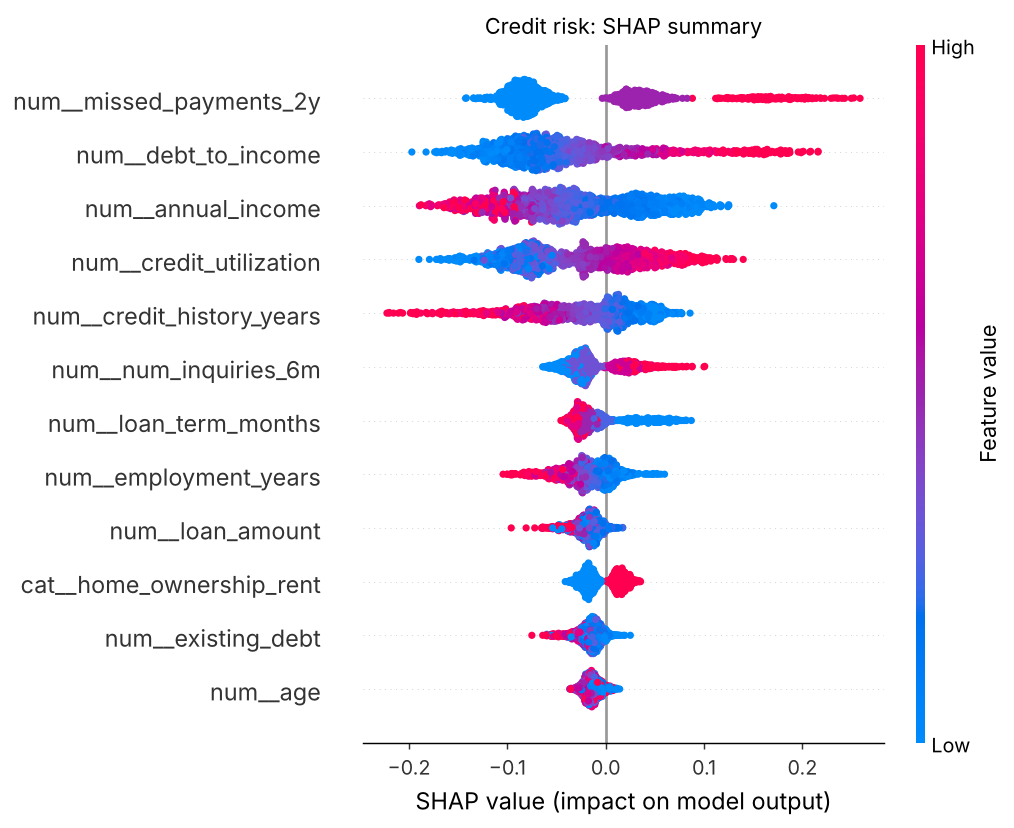

Applicant risk (PD) = 0.92 -> reason codes:
  - Recent missed payments  (SHAP +0.153)
  - High debt-to-income ratio  (SHAP +0.133)
  - Low income  (SHAP +0.075)
  - High credit utilisation  (SHAP +0.054)


In [17]:
rf_B = fitted_B["Random Forest"]
tu.shap_summary(rf_B, XB_te.sample(1500, random_state=1), "credit_shap_summary.png", "Credit risk: SHAP summary")
display(Image(str(tu.REPORTS_DIR / "credit_shap_summary.png")))

REASONS = {"debt_to_income": "High debt-to-income ratio", "missed_payments_2y": "Recent missed payments",
           "credit_utilization": "High credit utilisation", "num_inquiries_6m": "Many recent credit enquiries",
           "credit_history_years": "Short credit history", "employment_years": "Short employment history",
           "annual_income": "Low income", "loan_amount": "Large loan amount", "existing_debt": "High existing debt"}
i = int(np.argmax(scores_B["Random Forest"])); row = XB_te.iloc[[i]]
top = tu.top_reasons(rf_B, row, k=4)
print(f"Applicant risk (PD) = {scores_B['Random Forest'][i]:.2f} -> reason codes:")
for f, v in top.items():
    base = f.split("__", 1)[-1]
    print(f"  - {REASONS.get(base, base)}  (SHAP +{v:.3f})")

## 4. Save models and metric tables

In [18]:
tu.save_model({"pipeline": fitted_A["Random Forest"], "threshold": THRESH_A, "tiers": tiers_A, "features": feats_A}, "upi_fraud_rf")
tu.save_model({"pipeline": fitted_B["Random Forest"], "threshold": t_B, "features": feats_B}, "credit_risk_rf")
tu.save_model({"pipeline": sc_pipe, "features": feats_B}, "credit_scorecard_lr")
cv_A.to_csv(tu.REPORTS_DIR / "upi_cv_metrics.csv", index=False)
hold_A.to_csv(tu.REPORTS_DIR / "upi_holdout_metrics.csv")
imb_A.to_csv(tu.REPORTS_DIR / "upi_imbalance_comparison.csv", index=False)
cv_B.to_csv(tu.REPORTS_DIR / "credit_cv_metrics.csv", index=False)
hold_B.to_csv(tu.REPORTS_DIR / "credit_holdout_metrics.csv")
print(sorted(p.name for p in tu.MODELS_DIR.glob("*.joblib")))
print(sorted(p.name for p in tu.REPORTS_DIR.glob("*")))

['credit_risk_rf.joblib', 'credit_scorecard_lr.joblib', 'mule_rf.joblib', 'upi_fraud_rf.joblib']
['.gitkeep', 'credit_cv_metrics.csv', 'credit_holdout_metrics.csv', 'credit_model_comparison.png', 'credit_pr.png', 'credit_roc.png', 'credit_shap_summary.png', 'eda_overview.png', 'fairness_age.csv', 'fairness_gender.csv', 'mule_feature_importance.csv', 'mule_metrics.csv', 'mule_network.png', 'mule_scored_accounts.csv', 'upi_calibration.png', 'upi_confusion.png', 'upi_cv_metrics.csv', 'upi_holdout_metrics.csv', 'upi_imbalance_comparison.csv', 'upi_learning_curve.png', 'upi_model_comparison.png', 'upi_pr.png', 'upi_roc.png', 'upi_shap_summary.png', 'upi_tier_report.csv', 'upi_timesplit_metrics.csv', 'upi_timesplit_pr.png', 'upi_timesplit_roc.png', 'upi_tuning.csv']


## 5. Summary template for your report
Fill in from the tables above: best model per module, PR-AUC vs accuracy contrast, SMOTE vs class weights, chosen threshold and the cost trade-off, Isolation Forest vs supervised gap, top SHAP drivers, fairness findings, and the limitation that data is synthetic.